# Pothole Detection with YOLO + Roboflow (Google Colab)

Train a pothole detector on an open-source Roboflow Universe dataset, evaluate it, then run it on a road video.

**Before you start:** Runtime > Change runtime type > **T4 GPU**.

## 1. Setup

In [1]:
!nvidia-smi
!pip install -q ultralytics roboflow

Sun Nov 22 14:59:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Download the dataset from Roboflow

1. Create a free account at roboflow.com and copy your **Private API key** (Settings > API Keys).
2. In Colab, add it as a secret named `ROBOFLOW_API_KEY` (key icon in the left sidebar) and enable notebook access.

Dataset used: **roboflow_potholes** by `pothole-vsmtu` on Roboflow Universe
(https://universe.roboflow.com/pothole-vsmtu/roboflow_potholes), about 650 images.
If you want a different pothole dataset, change the three variables below (open any dataset on Universe, click *Download Dataset*, choose *YOLOv11* format, and copy the workspace/project/version).

In [2]:
from roboflow import Roboflow
from google.colab import userdata
rf = Roboflow(api_key="api key")
project = rf.workspace("pothole-vsmtu").project("roboflow_potholes")
version = project.version(1)
dataset = version.download("yolo26")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to roboflow_potholes-1 in yolo26:: 100%|██████████| 1315/1315 [00:00<00:00, 5103.17it/s]


## 3. Inspect the dataset

In [3]:
import yaml, glob, os

with open(f"{dataset.location}/data.yaml") as f:
    cfg = yaml.safe_load(f)
print("Classes:", cfg["names"])

for split in ["train", "valid", "test"]:
    n = len(glob.glob(f"{dataset.location}/{split}/images/*"))
    print(f"{split}: {n} images")

Classes: ['0']
train: 522 images
valid: 68 images
test: 65 images


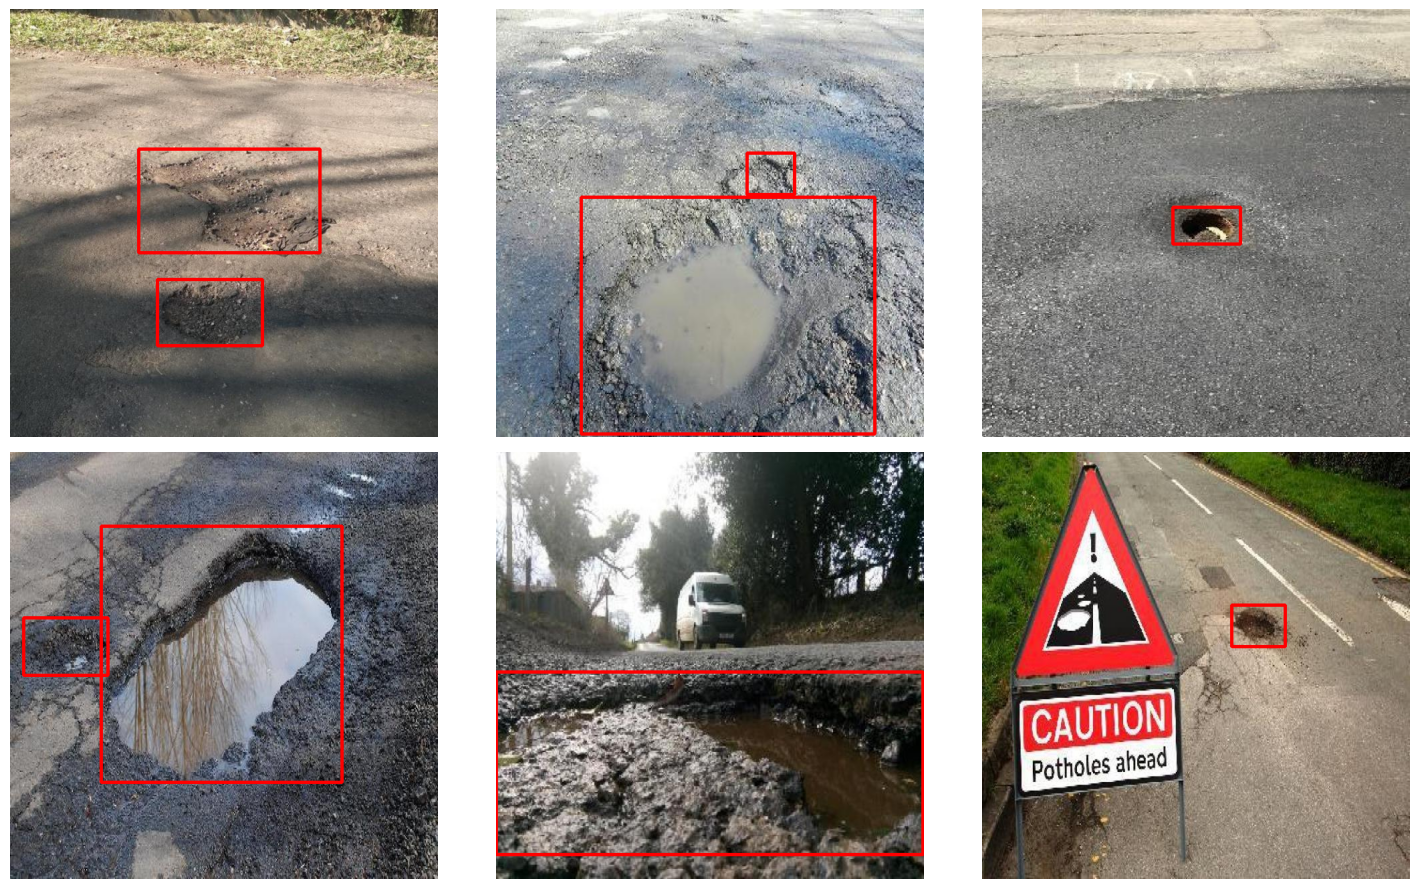

In [4]:
import random, cv2
import matplotlib.pyplot as plt

imgs = glob.glob(f"{dataset.location}/train/images/*")
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, p in zip(axes.flat, random.sample(imgs, 6)):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lbl = p.replace("images", "labels").rsplit(".", 1)[0] + ".txt"
    if os.path.exists(lbl):
        for line in open(lbl):
            _, x, y, bw, bh = map(float, line.split()[:5])
            x1, y1 = int((x - bw/2) * w), int((y - bh/2) * h)
            x2, y2 = int((x + bw/2) * w), int((y + bh/2) * h)
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 3)
    ax.imshow(img); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Train

We fine-tune a small pretrained YOLO model (transfer learning). `yolo11n` is fast and fits comfortably on a free T4.

In [5]:
from ultralytics import YOLO

model = YOLO("yolo26s.pt")
results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=80,
    imgsz=640,
    batch=16,
    patience=15,     # early stopping
    project="runs",
    name="pothole",
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/roboflow_potholes-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fracti

## 5. Evaluate

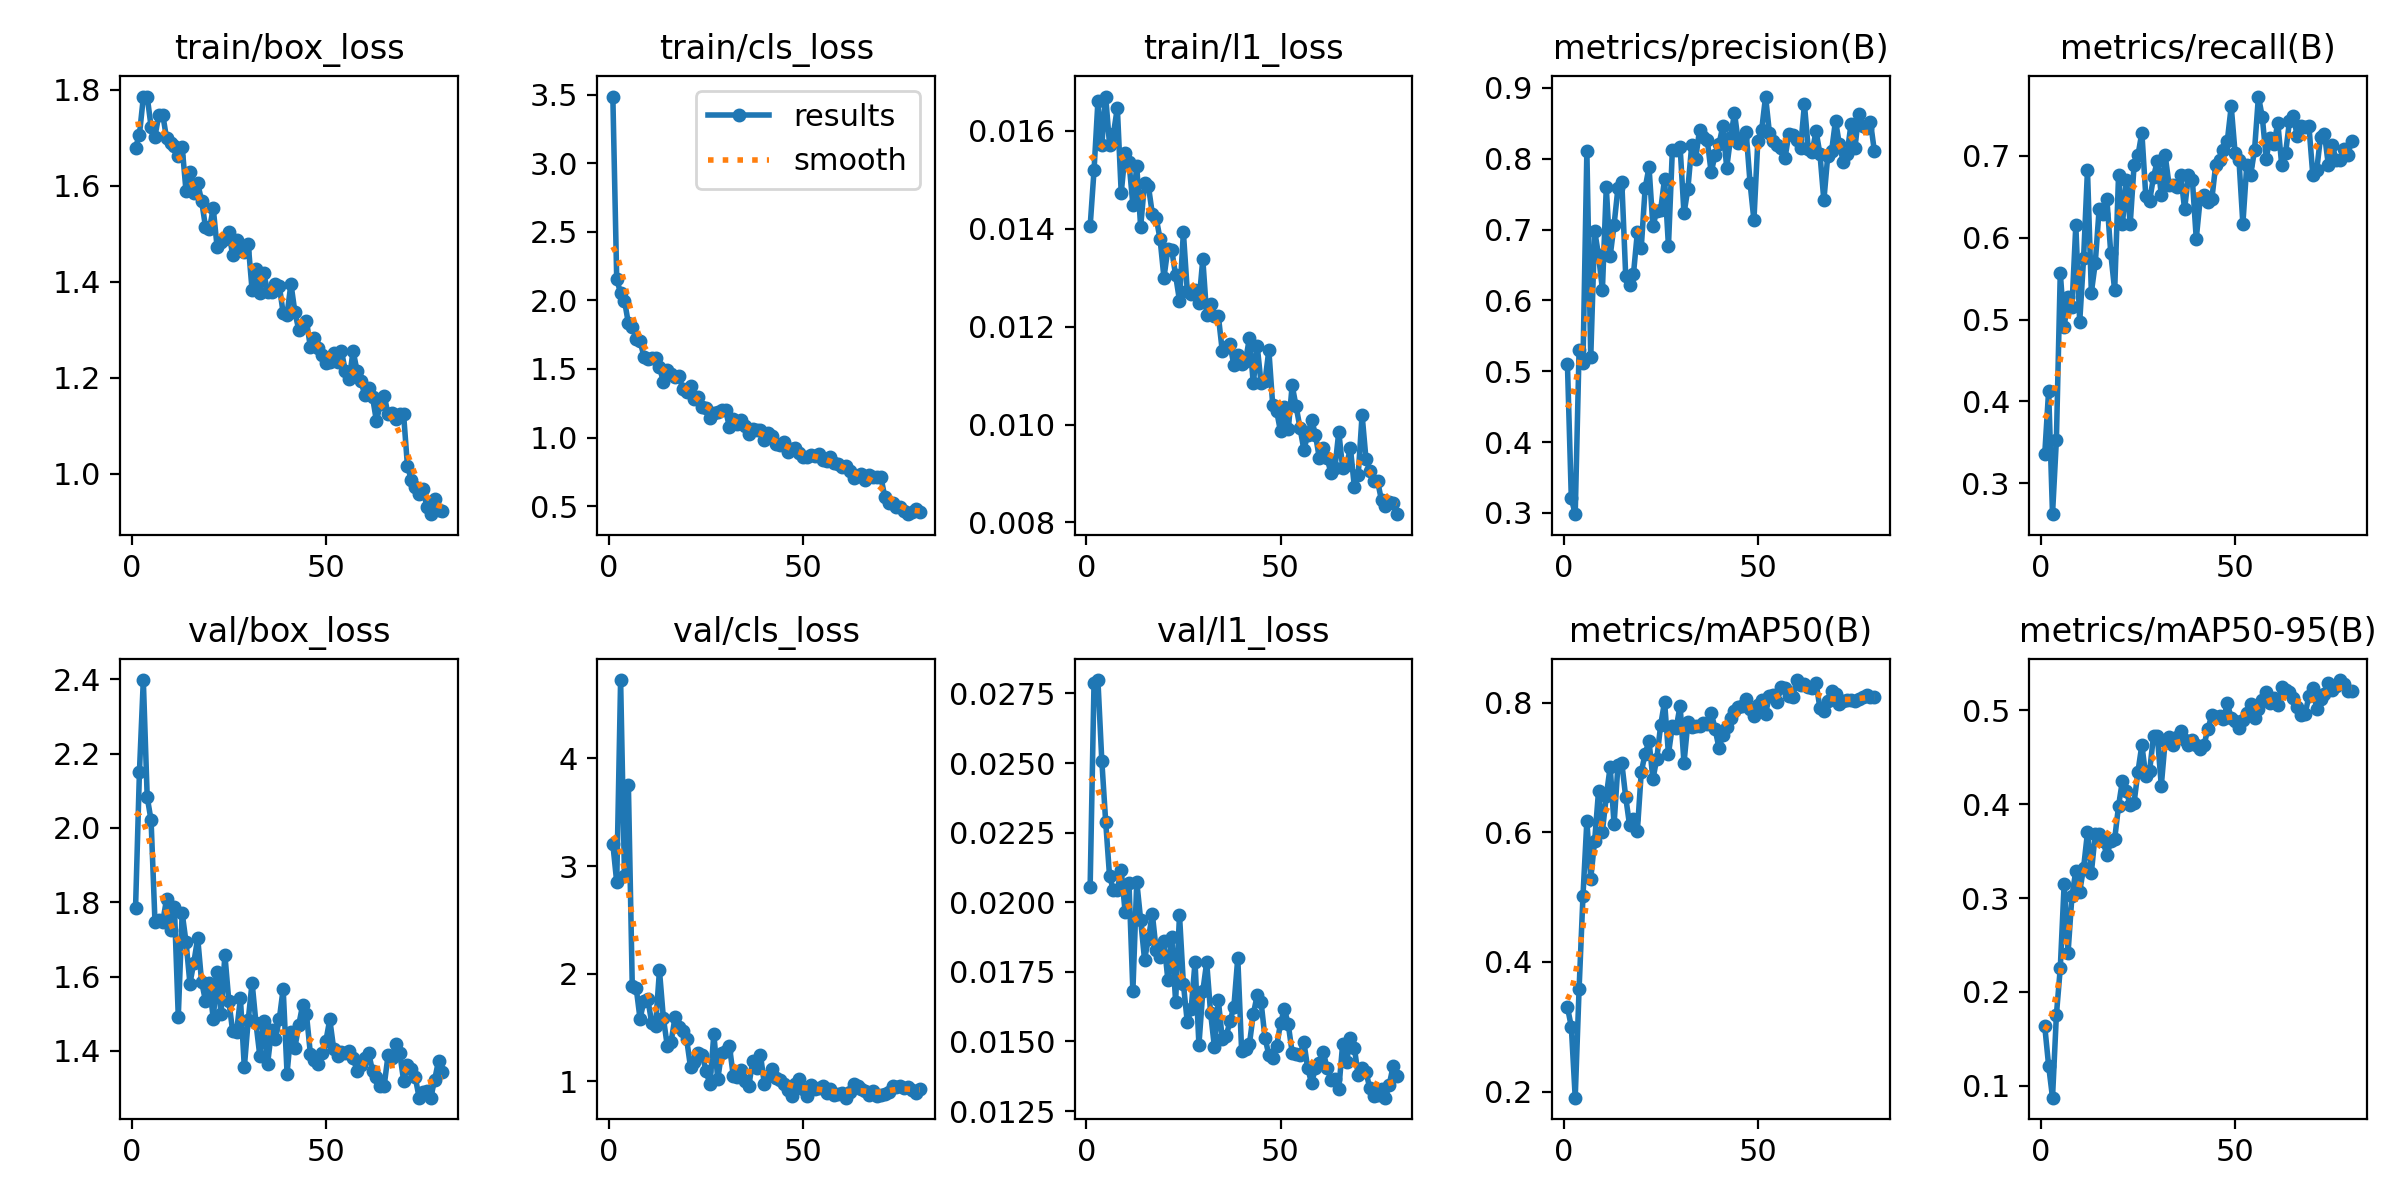

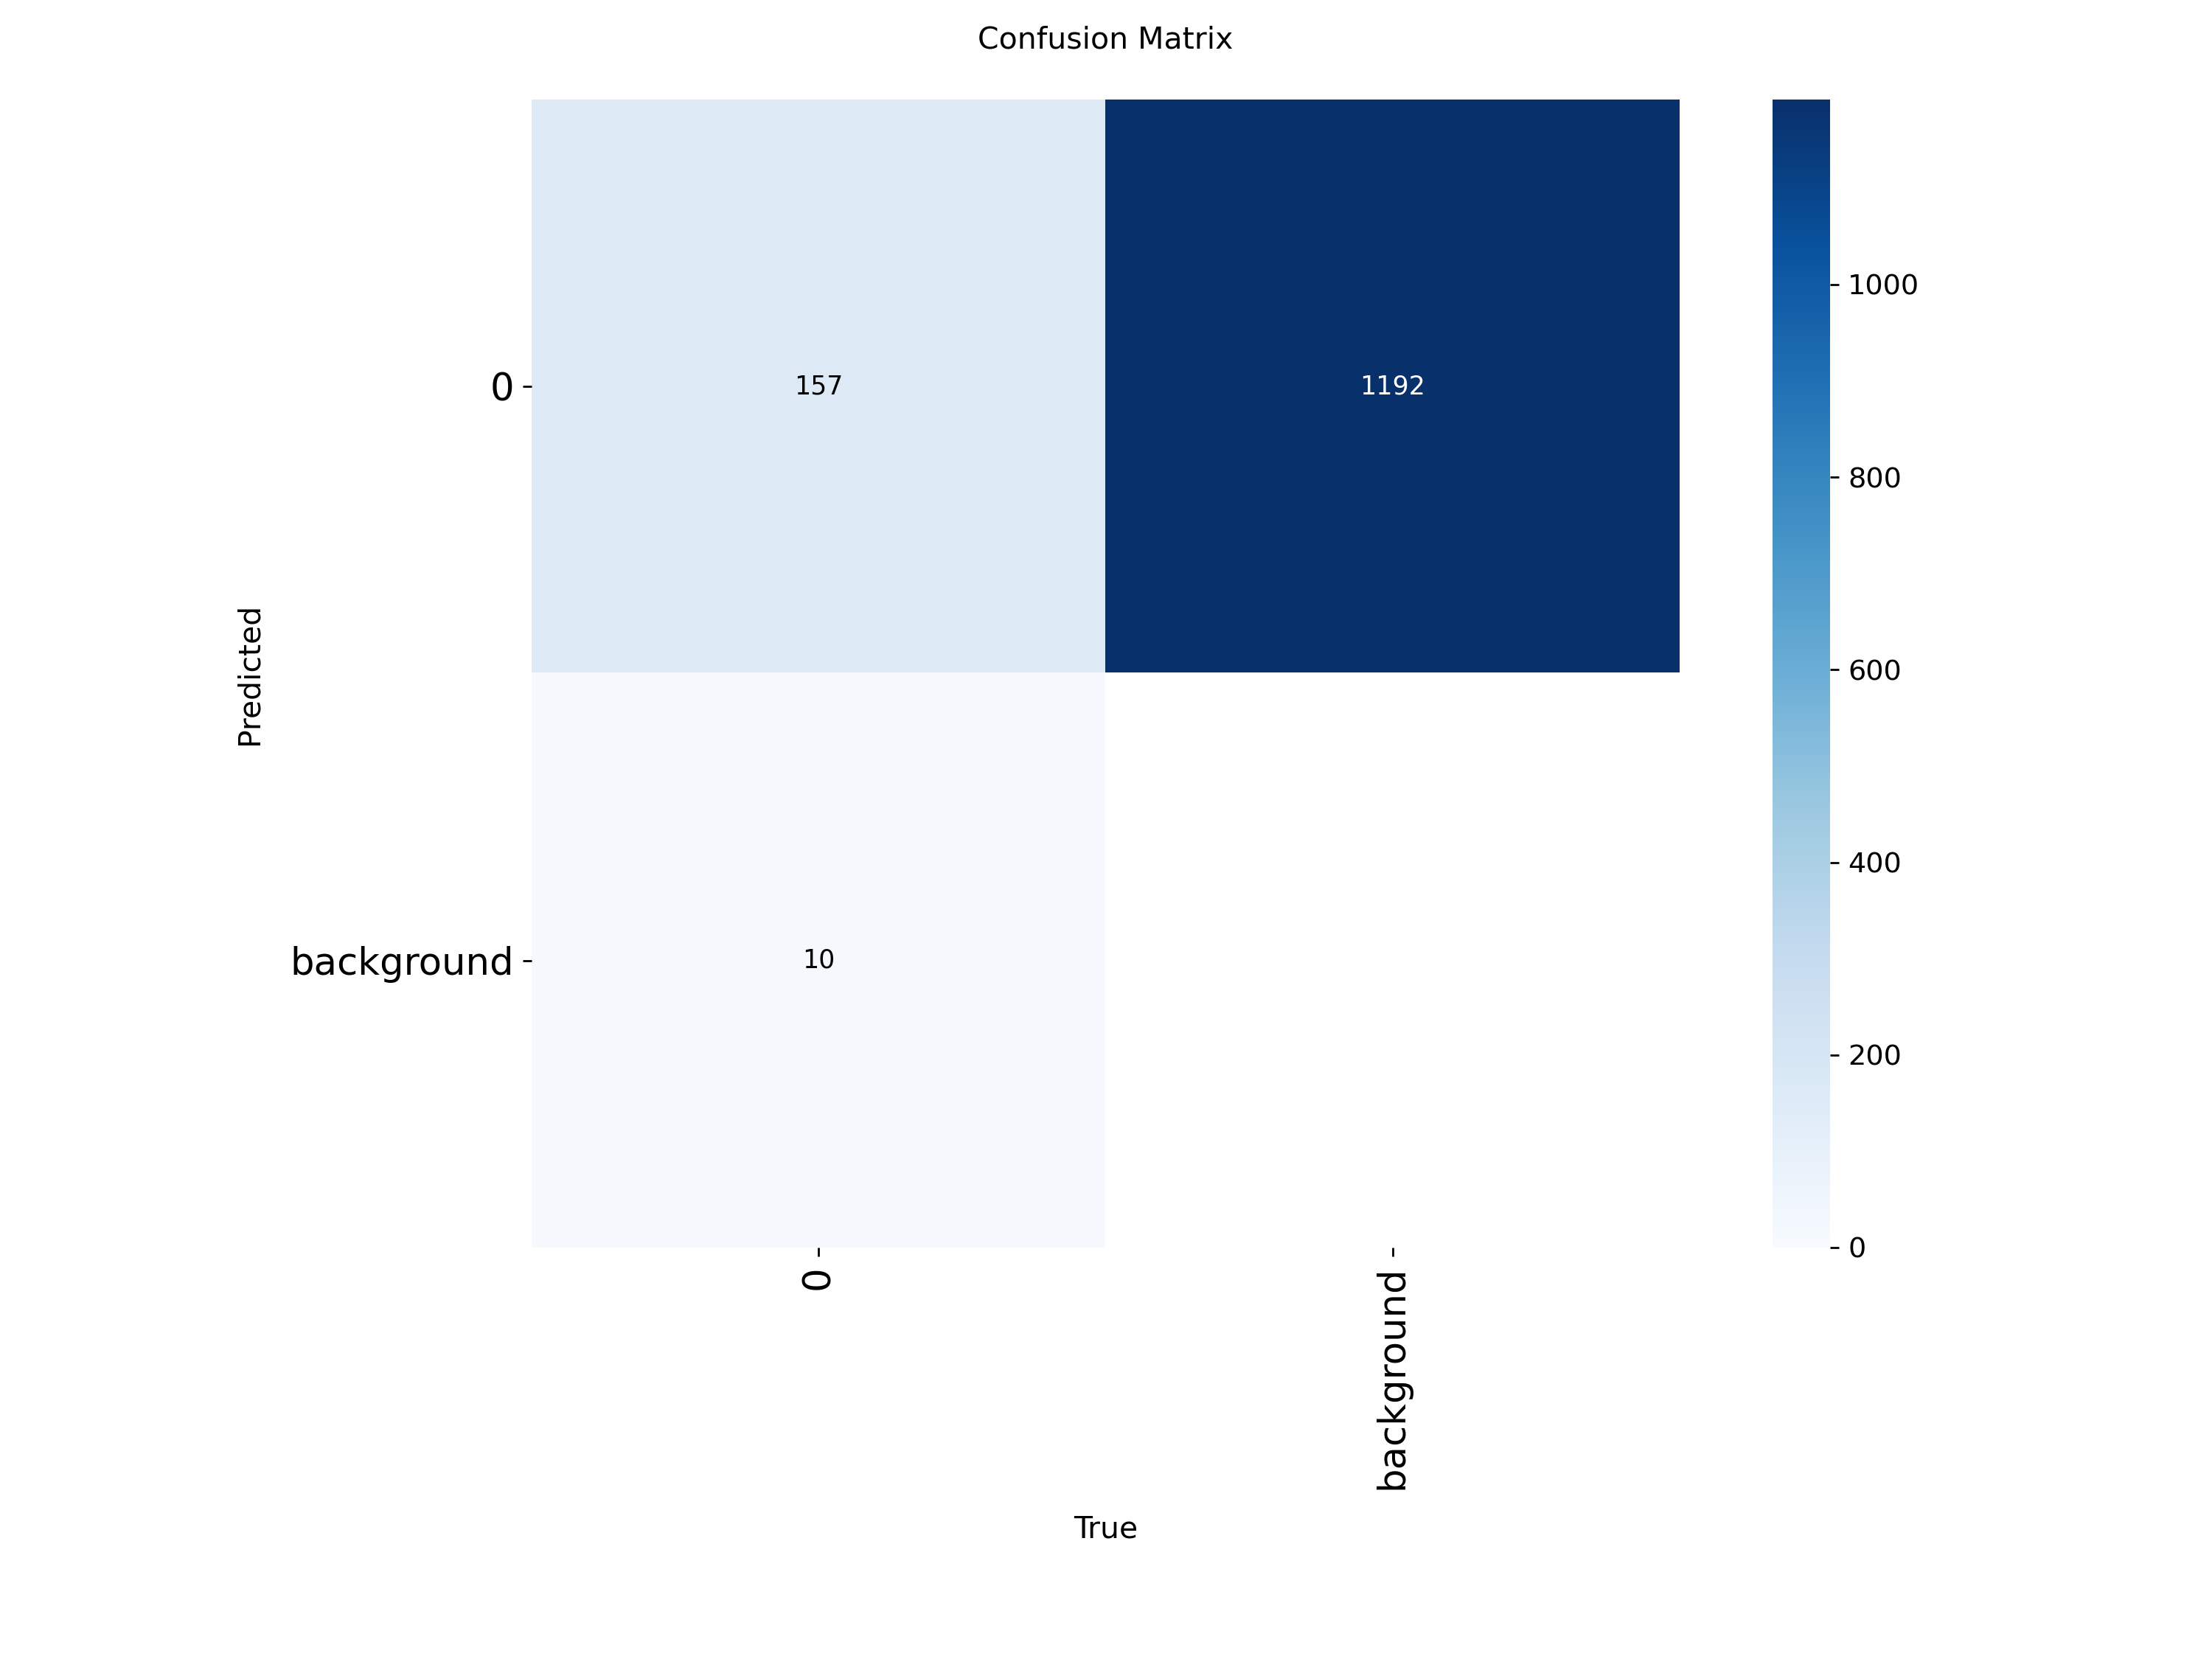

In [6]:
from IPython.display import Image, display

run_dir = "runs/detect/runs/pothole"
display(Image(f"{run_dir}/results.png", width=900))
display(Image(f"{run_dir}/confusion_matrix.png", width=600))

In [7]:
best = YOLO(f"{run_dir}/weights/best.pt")
metrics = best.val(data=f"{dataset.location}/data.yaml", split="test")
print(f"mAP@50:    {metrics.box.map50:.3f}")
print(f"mAP@50-95: {metrics.box.map:.3f}")
print(f"Precision: {metrics.box.mp:.3f}")
print(f"Recall:    {metrics.box.mr:.3f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 13.5±4.9 MB/s, size: 77.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/roboflow_potholes-1/test/labels... 65 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 65/65 310.1it/s 0.2s
val: New cache created: /content/roboflow_potholes-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.4it/s 2.1s
                   all         65        151      0.845      0.742      0.852       0.55
Speed: 3.3ms preprocess, 11.7ms inference, 0.1ms loss, 3.4ms postprocess per image
Results saved to /content/runs/detect/val
mAP@50:    0.852
mAP@50-95: 0.550
Precision: 0.845
Re


0: 640x640 2 0s, 12.3ms
1: 640x640 1 0, 12.3ms
2: 640x640 2 0s, 12.3ms
3: 640x640 1 0, 12.3ms
4: 640x640 2 0s, 12.3ms
5: 640x640 4 0s, 12.3ms
Speed: 1.4ms preprocess, 12.3ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)


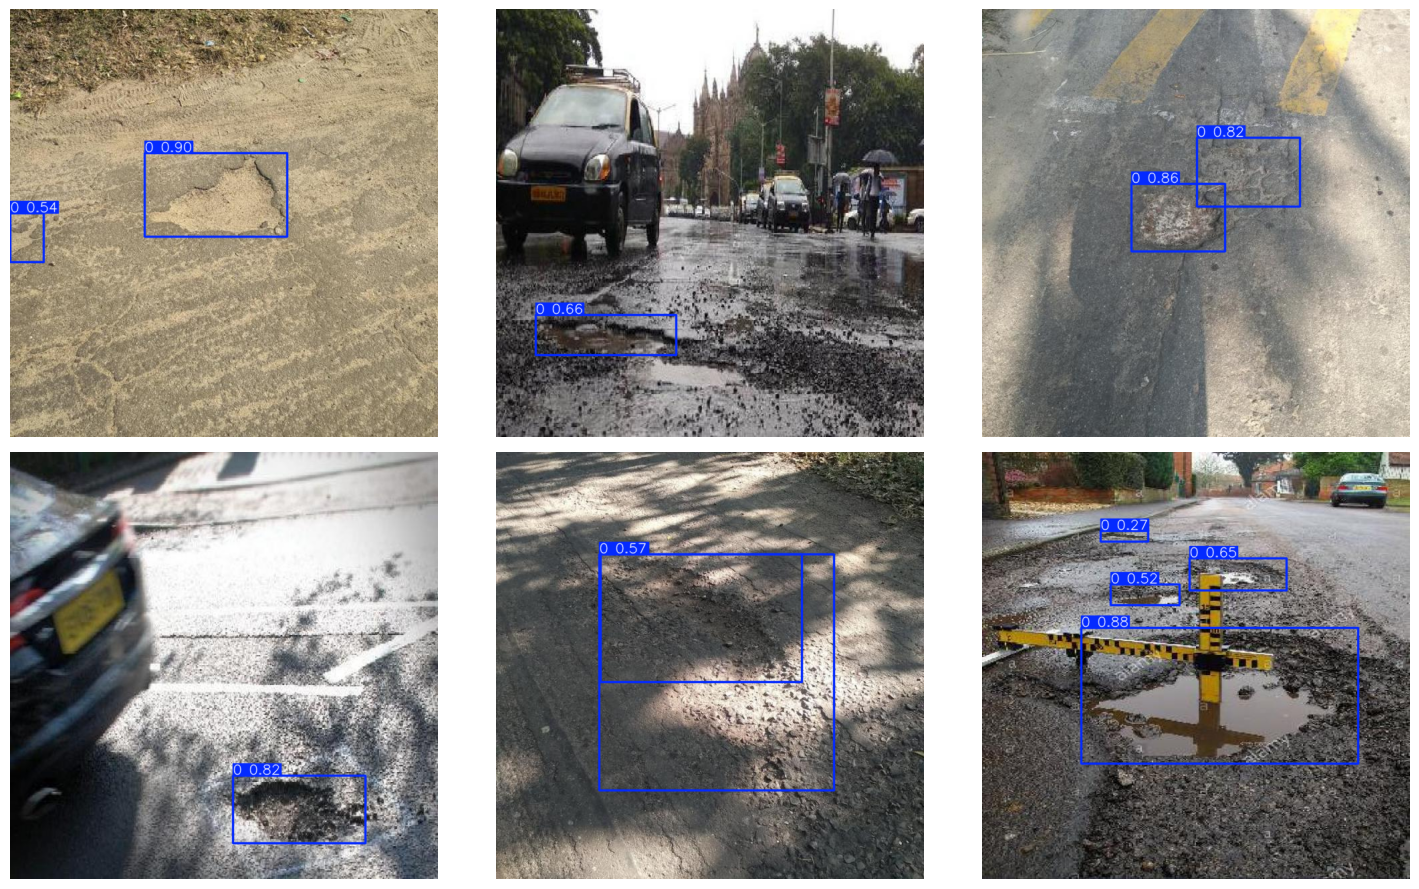

In [8]:
# Look at predictions on a few test images (check the failures too!)
test_imgs = glob.glob(f"{dataset.location}/test/images/*")[:6]
preds = best.predict(test_imgs, conf=0.25)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, r in zip(axes.flat, preds):
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Run on a video

Option A: upload your own dashcam / phone clip (recommended, it makes the tutorial original).
Option B: download any road video with `wget` or `yt-dlp` (only use footage you have the rights to).

In [9]:
from google.colab import files

uploaded = files.upload()          # pick your road video
VIDEO_PATH = list(uploaded.keys())[0]
print("Using:", VIDEO_PATH)

Saving mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4 to mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4
Using: mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4


In [11]:
from ultralytics import YOLO

#best = YOLO("/content/best_f.pt")
VIDEO_PATH = "/content/mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4"
print(best.names)   # should list your pothole class(es)

{0: '0'}


In [12]:
results = best.predict(
    source=VIDEO_PATH,
    conf=0.3,
    save=True,
    project="runs",
    name="video_out",
    exist_ok=True,
)
print("Done. Output folder: runs/detect/runs/video_out")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/692) /content/mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4: 384x640 12 0s, 14.3ms
video 1/1 (frame 2/692) /content/mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4: 384x640 10 0s, 18.4ms
video 1/1 (frame 3/692) /content/mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4: 384x640 11 0s, 12.4ms
video 1/1 (frame 4/692) /content/mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4: 384x640 11 0s, 11.9ms
video 1/1 (frame 5/692) /conten

## 7. Optional extras

**Count unique potholes with tracking** (each pothole counted once):

In [13]:
seen_ids = set()
for r in best.track(source=VIDEO_PATH, conf=0.3, persist=True, tracker="bytetrack.yaml", stream=True):
    if r.boxes.id is not None:
        seen_ids.update(r.boxes.id.int().tolist())
print("Unique potholes detected:", len(seen_ids))


video 1/1 (frame 1/692) /content/mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4: 384x640 (no detections), 12.3ms
video 1/1 (frame 2/692) /content/mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4: 384x640 7 0s, 16.2ms
video 1/1 (frame 3/692) /content/mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4: 384x640 10 0s, 13.4ms
video 1/1 (frame 4/692) /content/mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4: 384x640 11 0s, 13.7ms
video 1/1 (frame 5/692) /content/mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4: 384x640 10 0s, 18.4ms
video 1/1 (frame 6/692) /content/mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4: 384x640 9 0s, 21.0ms
video 1/1 (frame 7/692) /content/mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4: 384x640 8 0s, 13.4ms
video 1/1 (frame 8/692) /content/mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4: 384x640 9 0s, 13.6ms
video 1/1 (frame 9/692) /content/mixkit-potholes-in-a-rural-road-25208-hd-ready.mp4: 384x640 10 0s, 11.8ms
video 1/1 (frame 10/692) /cont

## Improving the model

- If detections are weak on your own footage, extract frames from your video, label them in Roboflow, add them to the dataset, and retrain.
- Try a larger model (`yolo11s.pt` / `yolo11m.pt`), more epochs, or Roboflow augmentations.
- Test on hard cases: wet roads, shadows, night, and speed bumps (a common false positive).